In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = sns.load_dataset('titanic')
print("Dataset loaded successfully!")
print("Dataset shape:",df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print("Dataset Information:")
df.info()
print("\nDataset Shape:")
print(df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nStatiscal Summary:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

Dataset Shape:
(891, 15)

Column Names:
['survived', 'pcl

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


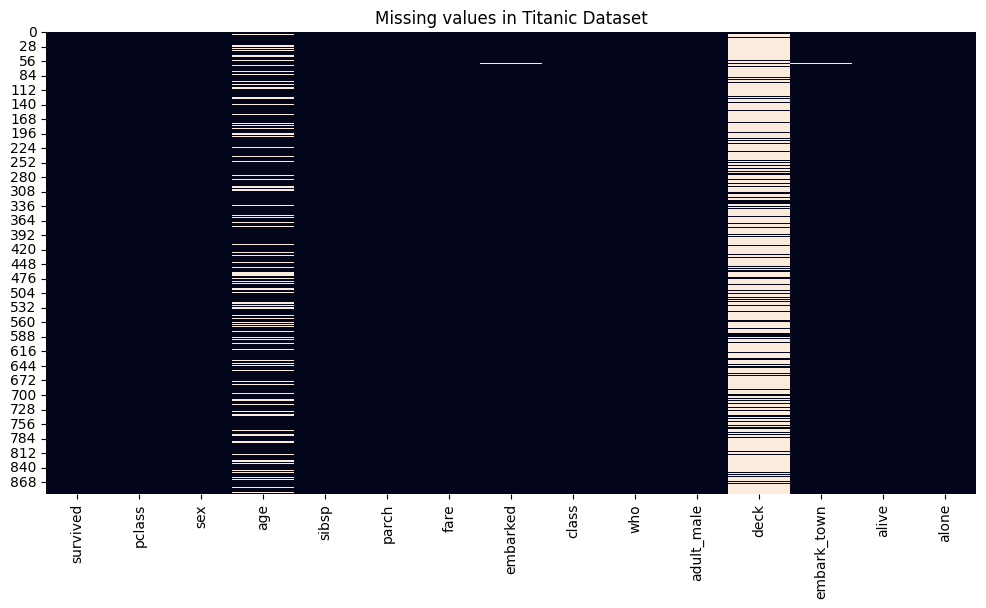

In [5]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(),cbar=False)
plt.title("Missing values in Titanic Dataset")
plt.show()

In [6]:
df = df.copy()
df = df.drop_duplicates()

df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
print("Data cleaning completed!")
print("Remaining missing values:")
print(df.isnull().sum())

Data cleaning completed!
Remaining missing values:
survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           582
embark_town      2
alive            0
alone            0
dtype: int64


In [7]:
print("Survival Counts:")
print(df['survived'].value_counts())
print("\nSurvival Percentages:")
print((df['survived'].value_counts(normalize=True) * 100).round(2))

Survival Counts:
survived
0    461
1    323
Name: count, dtype: int64

Survival Percentages:
survived
0    58.8
1    41.2
Name: proportion, dtype: float64


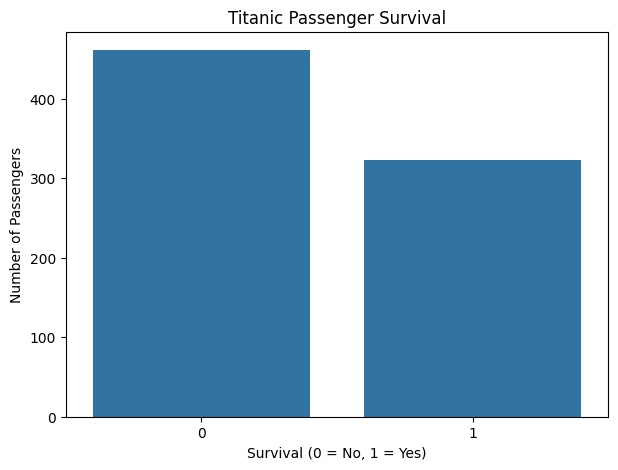

In [8]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='survived')
plt.title("Titanic Passenger Survival")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

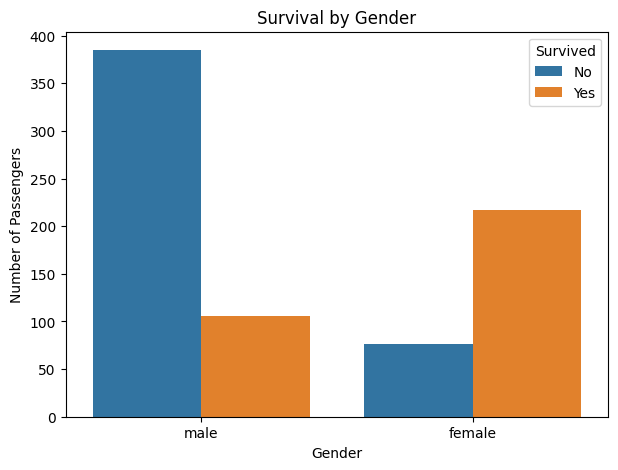

In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='sex', hue='survived')
plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()

In [11]:
gender_survival = (
    df.groupby('sex', observed=True)['survived']
    .mean()
    .mul(100)
    .round(2))
print("Survival percentage by gender:")
print(gender_survival)

Survival percentage by gender:
sex
female    74.06
male      21.59
Name: survived, dtype: float64


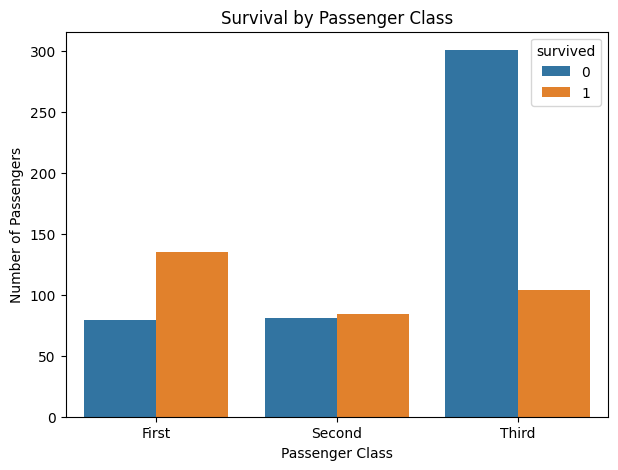

In [12]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='class', hue='survived')
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()

In [13]:
class_survival = (
    df.groupby('class', observed=True)['survived']
    .mean()
    .mul(100)
    .round(2)
)
print("Survival percentage by passenger class:")
print(class_survival)

Survival percentage by passenger class:
class
First     63.08
Second    50.91
Third     25.68
Name: survived, dtype: float64


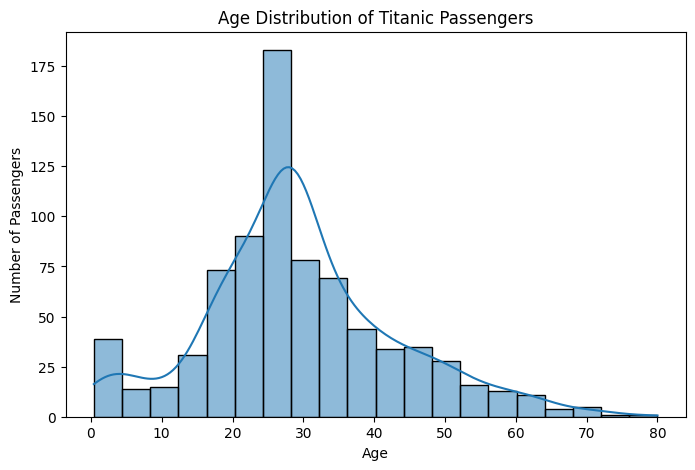

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='age', bins=20, kde=True)
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

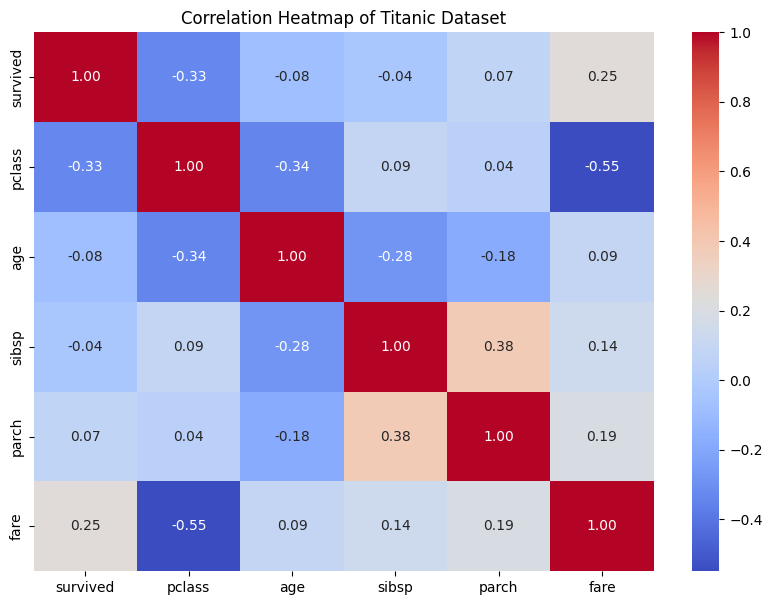

In [15]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f')
plt.title("Correlation Heatmap of Titanic Dataset")
plt.show()

Conclusion

Exploratory Data Analysis was performed on the Titanic passenger dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The analysis included examining the dataset structure, identifying missing values, cleaning selected columns, and exploring passenger survival patterns.

Visualizations were created to compare survival by gender and passenger class to examine the age distribution and correlations among numerical variables.

The analysis helps identify patterns associated with survival. However, these patterns show associations rather than proving that any particular characteristic caused a passenger to survive.

This project demonstrates fundamental data science skills, including data loading, data cleaning, statistical analysis, and data visualization.